In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

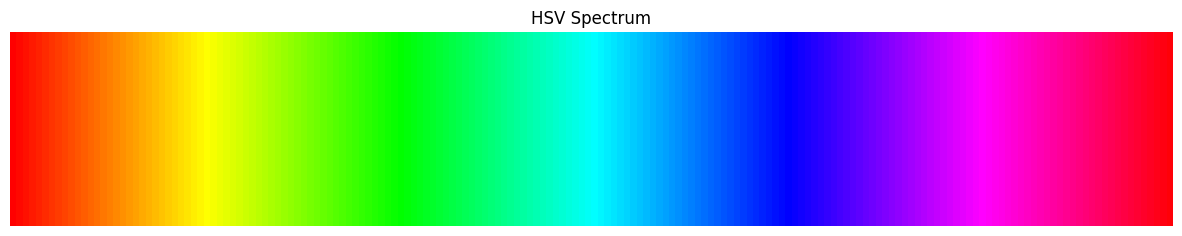

In [3]:
hue_spectrum = np.linspace(0, 179, num=180, dtype="uint8")

hue_image = np.array([hue_spectrum] * 30)

saturation_channel = np.ones_like(hue_image, dtype="uint8") * 255

value_channel = np.ones_like(hue_image, dtype="uint8") * 255

hsv_image = cv2.merge([hue_image, saturation_channel, value_channel])

bgr_image = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2BGR)

plt.figure(figsize=(15, 3))

plt.imshow(cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB))
plt.title("HSV Spectrum")
plt.axis("off")

plt.show()

In [4]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_image(keyword, fallback_index):
  matches = [
      name for name in uploaded_names if keyword.lower() in name.lower()
  ]

  if matches:
    return '/content/' + matches[0]

  if fallback_index < len(uploaded_names):
    return '/content/' + uploaded_names[fallback_index]
  raise FileExistsError(f'Image Not Found: {keyword}')

felfel_path = find_uploaded_image('felfel-dolme', 0)
akhavan_path = find_uploaded_image('akhavan', 1)

print(felfel_path)
print(akhavan_path)

Saving akhavan.jpg to akhavan.jpg
Saving felfel-dolme.jpg to felfel-dolme.jpg
/content/felfel-dolme.jpg
/content/akhavan.jpg


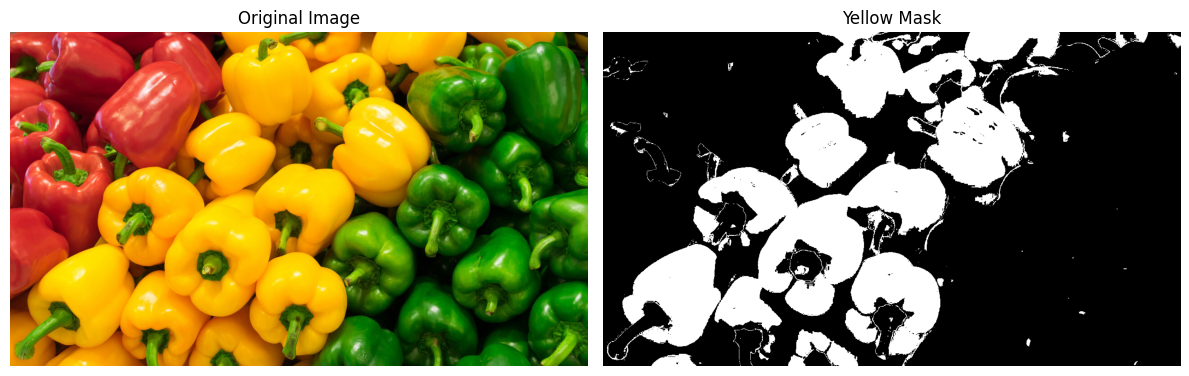

In [5]:
felfel_image = cv2.imread(felfel_path)
if felfel_image is None:
  raise FileExistsError(felfel_path)

felfel_hsv = cv2.cvtColor(felfel_image, cv2.COLOR_BGR2HSV)

lower_yellow = np.array([20, 50, 50])
upper_yellow = np.array([30, 255, 255])

yellow_mask = cv2.inRange(felfel_hsv, lower_yellow, upper_yellow)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(felfel_image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(yellow_mask, cmap="gray")
plt.title("Yellow Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

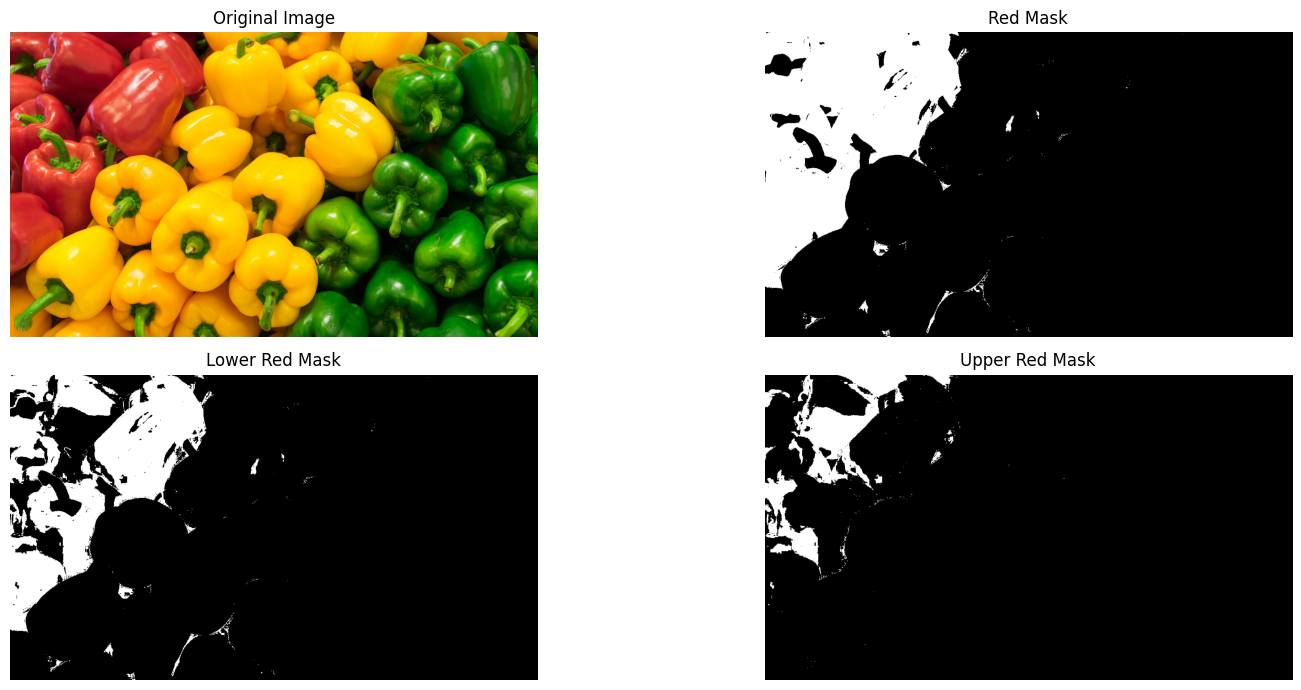

In [6]:
lower_red_1 = np.array([0, 50, 50])
upper_red_1 = np.array([10, 255, 255])

lower_red_2 = np.array([160, 50, 50])
upper_red_2 = np.array([179, 255, 255])

red_mask_lower = cv2.inRange(felfel_hsv, lower_red_1, upper_red_1)
red_mask_upper = cv2.inRange(felfel_hsv, lower_red_2, upper_red_2)

red_mask = cv2.bitwise_or(red_mask_lower, red_mask_upper)

plt.figure(figsize=(17, 7))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(felfel_image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(red_mask, cmap="gray")
plt.title('Red Mask')
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(red_mask_lower, cmap="gray")
plt.title("Lower Red Mask")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(red_mask_upper, cmap="gray")
plt.title("Upper Red Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

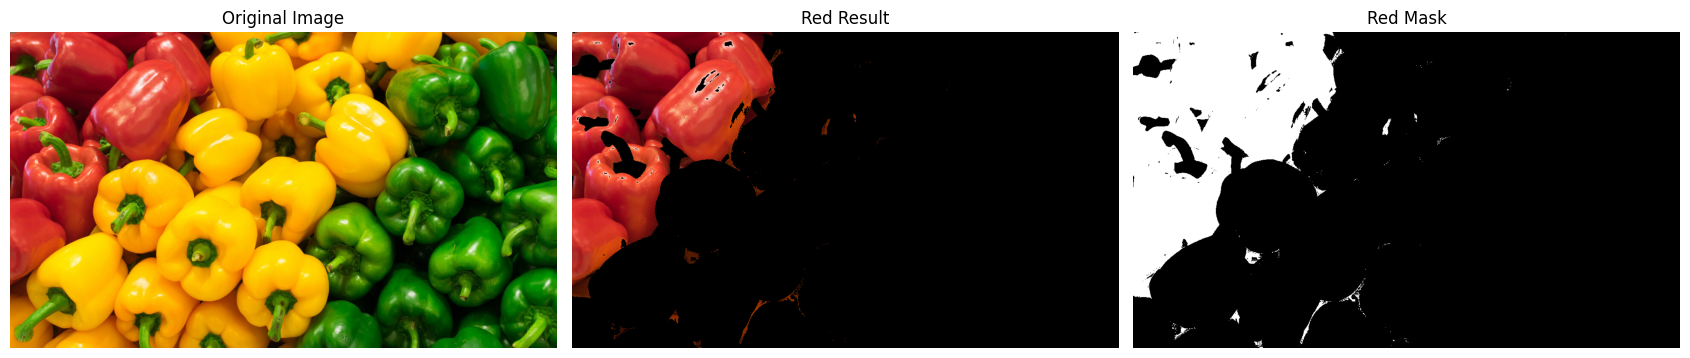

In [7]:
red_result_felfel = cv2.bitwise_and(felfel_image, felfel_image, mask=red_mask)

plt.figure(figsize=(17, 7))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(felfel_image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(red_result_felfel, cv2.COLOR_BGR2RGB))
plt.title("Red Result")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(red_mask, cmap="gray")
plt.title("Red Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

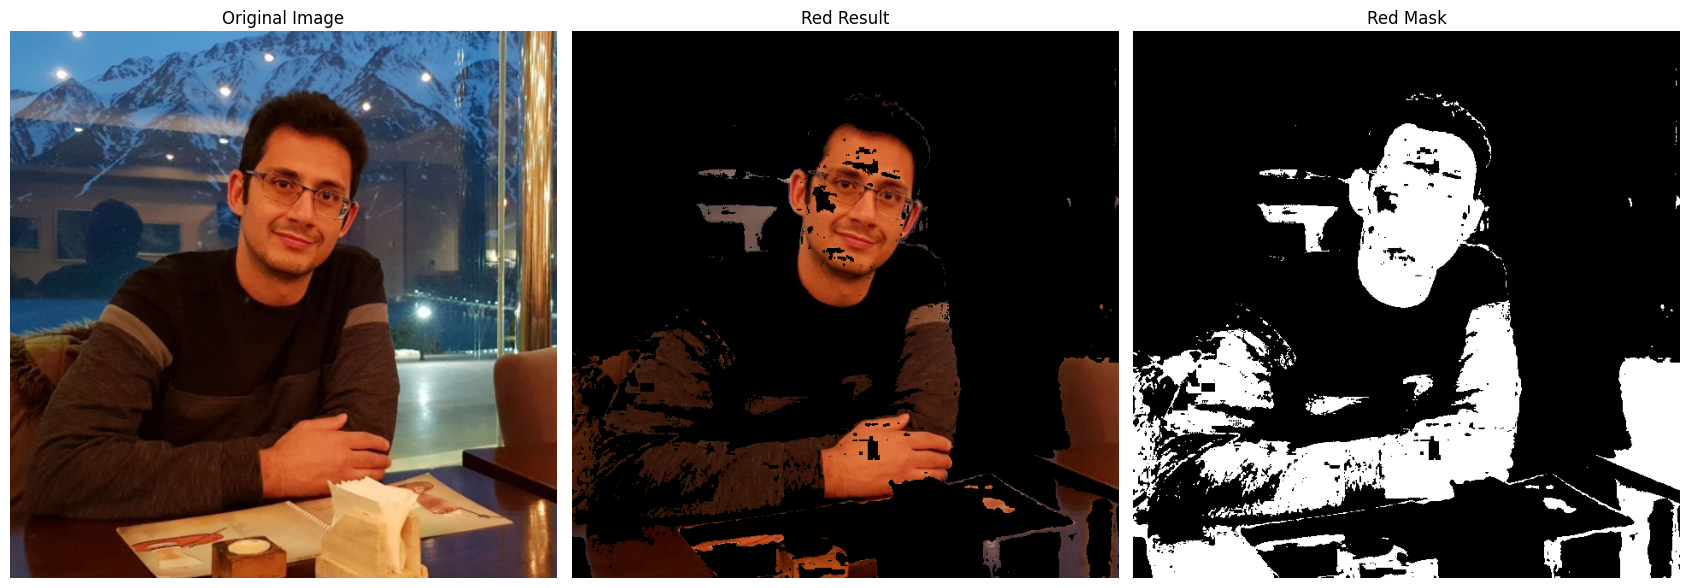

In [8]:
akhavan_image = cv2.imread(akhavan_path)
if akhavan_image is None:
  raise FileExistsError(akhavan_path)

akhavan_hsv = cv2.cvtColor(akhavan_image, cv2.COLOR_BGR2HSV)

akhavan_mask_lower = cv2.inRange(akhavan_hsv, lower_red_1, upper_red_1)
akhavan_mask_upper = cv2.inRange(akhavan_hsv, lower_red_2, upper_red_2)

akhavan_mask = cv2.bitwise_or(akhavan_mask_lower, akhavan_mask_upper)

akhavan_result = cv2.bitwise_and(akhavan_image, akhavan_image, mask=akhavan_mask)

plt.figure(figsize=(17, 7))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(akhavan_image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(akhavan_result, cv2.COLOR_BGR2RGB))
plt.title("Red Result")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(akhavan_mask, cmap="gray")
plt.title("Red Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
output_images = {
    'felfel_mask': yellow_mask,
    'felfel_result': red_result_felfel,
    'akhavan_mask': akhavan_mask,
    'akhavan_result': akhavan_result
}

for filename, output_image in output_images.items():
  output_path = '/content/' + filename
  cv2.imwrite(filename + '.png', output_image)
  print(f'Saved: {output_path}')
  files.download(filename + '.png')
  print(f'Downloaded: {output_path}')

Saved: /content/felfel_mask


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/felfel_mask
Saved: /content/felfel_result


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloaded: /content/akhavan_mask
Saved: /content/akhavan_result


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/akhavan_result
